# HFGradInv(AAAI'24): Recovering CelebA-HQ in ResNet-18 (Kaiming-Normal).
📅 **Introduction** : This is the showcase of **HFGradInv(AAAI'24)**, relevant to **Fig. 5** in paper. Here are details of the attack scenario:
- Dataset: CelebA-HQ
- Data: Fixed & Random Sampled
- Model: ResNet-18 (**Kaiming-Normal** initialized)
- Data Amount: 1 (Batch Size = 1)
- Attacker Observations: Gradient (Epoch = 1)

🔖 **Reference**
- Paper: *Ye, Zipeng, et al. "High-fidelity gradient inversion in distributed learning." Proceedings of the AAAI Conference on Artificial Intelligence. Vol. 38. No. 18. 2024.*
- Implementations: [github:MiLab-HITSZ/2023YeHFGradInv](https://github.com/MiLab-HITSZ/2023YeHFGradInv)


⚠️ **Notes**: 
1. **Please install CelebA-HQ dataset if you need to reproduce.** Please refer to `readme.md` for more details.
2. **A different data might be sampled when you try showcase 2 (Random Sampled).** It is decided by hardware you used.
3. **Attack here will just perform** $1$ **time.** But in paper, we have retried $5$ times to report the best result.

## Environment Setup
⭕ **First, Import Dependencies**

See **README.md** for dependency installations.

In [1]:
import logging, sys
import warnings

import torch
from omegaconf import OmegaConf, open_dict

import breaching

# Redirects logs directly into the jupyter notebook
logging.basicConfig(level=logging.INFO, handlers=[logging.StreamHandler(sys.stdout)], format='%(message)s')
logger = logging.getLogger()

# filter warning logs
warnings.filterwarnings("ignore")

⭕ **Second, Loading Configurations**

Loading the configuration of **Use Case** and **Attack**.
- **Use Case** configuration: defined by `case_config`. It describes the use case of attack (i.e. which scenario it attacks on), including:
    - Dataset: CelebA-HQ
    - Data: random sampled
    - Model: ResNet-18 (Kaiming-Normal)
    - Details: Batch Size = 1, Epoch = 1
- **Attack** configuration: defined by `attack_config`. It describes the attack we want to use.

In [2]:
case_config = breaching.get_case_config(case="celeba_hq_identity_random_untrained_kaiming_normal_resnet18")
attack_config = breaching.get_attack_config(attack="HFGradInv")

# Experiment are preferred to perform on GPU. It will automatically turn to cpu if you have not equipped.
gpu = "cuda:0"
device = torch.device(gpu) if torch.cuda.is_available() else torch.device('cpu')
torch.backends.cudnn.benchmark = case_config.impl.benchmark
setup = dict(device=device, dtype=getattr(torch, case_config.impl.dtype))


Investigating use case celeba_hq_identity_random_untrained_kaiming_normal_resnet18 with server type honest_but_curious.
Loading attack configuration optimization-HFGradInv.


## Showcase 1: Fixed Sampling
📅 **Introduction**: In this show case, we will fixedly sample a data has been shown in **Fig. 5**.

✅ **Notes**: This showcase is reproducible.

⭕ **1.1 Specified the data we want to sample.**

- Split dataset to `num_classes` of clients. Each clients hold data with same label.
- We take the first client as **victim**, and take its first data as **private data** (i.e. ***target to recover***).

In [3]:
OmegaConf.set_struct(case_config, True)
with open_dict(case_config):
    case_config.data.partition="unique-class"
    case_config.data.default_clients = case_config.data.classes
    case_config.user.user_idx = 0

⭕ **1.2 Compute gradients, and plot the data we has been sampled** **(*target to recover*)**.

Attacker (servers) aims to recover it by observing its gradient. (i.e. `shared_update`)

Computing user update on user 0 in model mode: eval.


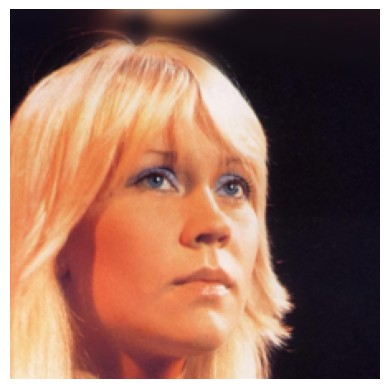

In [4]:
user, server, model, loss_fn = breaching.cases.construct_case(case_config, setup)
server_payload = server.distribute_payload()
shared_update, true_user_data = user.compute_local_updates(server_payload)

user.plot(true_user_data)

⭕ **1.3 Setup Attack.**

In [5]:
# `num_trials` specified the time for retrying.
# We skip retrying for conciseness here, and report result as it finished.
num_trials = 1
OmegaConf.set_struct(attack_config, True)
with open_dict(attack_config):
    attack_config.restarts.num_trials = num_trials

attacker = breaching.attacks.prepare_attack(
    model=server.model, 
    loss=server.loss, 
    cfg_attack=attack_config, 
    setup=setup
)

# You could also run following code for a glance of what you have configured.
# breaching.utils.overview(server, user, attacker)

⭕ **1.4 Recovering it by the configured attack.**

- This attack will be performed by observing its gradients (i.e. `shared_update`).
- The reconstruction is stored by `reconstructed_data`.

In [6]:
reconstructed_data, stats = attacker.reconstruct([server_payload], [shared_update], {})

Recovered labels [0] through strategy yin.
| It: 1 | Rec. loss: 100.0271 |  Task loss: 320.4868 | T: 0.22s
| It: 1001 | Rec. loss: 100.0023 |  Task loss: 490.3670 | T: 62.02s
| It: 2001 | Rec. loss: 100.0028 |  Task loss: 499.1354 | T: 81.19s
| It: 3001 | Rec. loss: 0.0177 |  Task loss: 455.2213 | T: 96.93s
| It: 4001 | Rec. loss: 0.0038 |  Task loss: 138.2006 | T: 93.06s
| It: 5001 | Rec. loss: 0.0034 |  Task loss: 139.2811 | T: 104.39s
| It: 6001 | Rec. loss: 0.0039 |  Task loss: 143.2199 | T: 105.06s
| It: 7001 | Rec. loss: 0.0036 |  Task loss: 137.8165 | T: 105.05s
| It: 8001 | Rec. loss: 0.0039 |  Task loss: 143.4213 | T: 105.08s
| It: 9001 | Rec. loss: 0.0035 |  Task loss: 141.6334 | T: 112.91s
| It: 10001 | Rec. loss: 0.0036 |  Task loss: 138.5306 | T: 114.23s
| It: 11001 | Rec. loss: 0.0038 |  Task loss: 141.5090 | T: 113.86s
| It: 12001 | Rec. loss: 0.0030 |  Task loss: 117.2708 | T: 113.78s
| It: 13001 | Rec. loss: 0.0030 |  Task loss: 97.0636 | T: 113.80s
| It: 14001 | Rec. 

⭕ **1.5 Evaluating the reconstruction qualitatively**

Three metrics will be evaluated for these two images (**reconstruction** and **private data**), including:
- **PSNR** $\uparrow$ : pixel-wise consistency between them.
- **LPIPS** $\downarrow$ : similarity of their latent representations from a same pretrained model.
- **SSIM** $\uparrow$ : similarity scoring of their overall structures, including luminance, contrast, and structure.

In [7]:
metrics = breaching.analysis.report(
    reconstructed_data, 
    true_user_data, 
    [server_payload], 
    server.model, 
    order_batch=True, 
    compute_full_iip=False, 
    cfg_case=case_config, 
    setup=setup
)

Starting evaluations for attack effectiveness report...
METRICS: | MSE: 0.0530 | PSNR: 12.76 | FMSE: 1.2192e+03 | LPIPS: 0.55|
 R-PSNR: 12.76 | IIP-pixel: 0.00% | SSIM: 0.3059 | max R-PSNR: 12.76 | max SSIM: 0.3059 | Label Acc: 100.00%


⭕ **1.6 Evaluating the reconstruction qualitatively**

 Plotting the data we have reconsturcted.

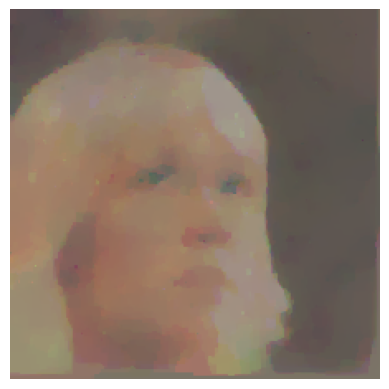

In [8]:
user.plot(reconstructed_data)

## Showcase 2: Random Sampling
📅 **Introduction**: In this show case, we will present the code for random sampling.

⚠️ **Notes**: A different data might be sampled when you reproduce. It is decided by hardware you used.

⭕ **2.1 Specified the seed we want to use.**

Specified the seed to perform randomly sampling.

⚠️ *Notes: A different data might be sampled when you reproduce. It is decided by hardware you used.*

In [9]:
# @ Notes: These are the seeds we have been generated and evaluated with
# @ Implementations: `seeds = torch.randint(0, 10000000, (20, ))`
#   seeds = [ 
#       6400942, 7261425, 982363,  8534671, 6679360, 
#       9001950, 2737937, 6241508, 8351731, 3572673, 
#       7101754, 6498150, 8152325, 5679244, 226193, 
#       1513304, 6483568, 9155478, 796668,  7593953
#   ]

case_config = breaching.get_case_config(case="celeba_hq_identity_random_untrained_kaiming_normal_resnet18")
seed = 9001950
OmegaConf.set_struct(case_config, True)
with open_dict(case_config):
    case_config.data.partition_seed = seed
breaching.utils.set_random_seed(seed)

Investigating use case celeba_hq_identity_random_untrained_kaiming_normal_resnet18 with server type honest_but_curious.


⭕ **2.2 Compute gradients, and plot the data we has been sampled** **(*target to recover*)**.

- This data is the **private data** held by the victim (i.e. the client). 
- Attacker (servers) aims to recover it by observing its gradient. (i.e. `shared_update`)

Computing user update on user 0 in model mode: eval.


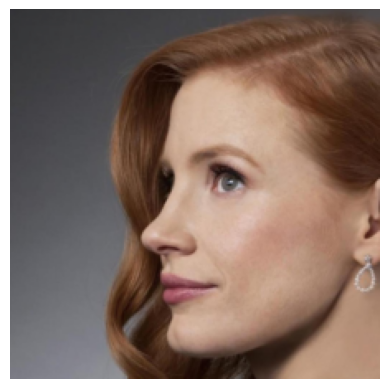

In [10]:
user, server, model, loss_fn = breaching.cases.construct_case(case_config, setup)
server_payload = server.distribute_payload()
shared_update, true_user_data = user.compute_local_updates(server_payload)

user.plot(true_user_data)


⭕ **2.3 Setup Attack.**

In [11]:
# `num_trials` specified the time for retrying.
# We skip retrying for conciseness here, and report result as it finished.
num_trials = 1
OmegaConf.set_struct(attack_config, True)
with open_dict(attack_config):
    attack_config.restarts.num_trials = num_trials

attacker = breaching.attacks.prepare_attack(
    model=server.model, 
    loss=server.loss, 
    cfg_attack=attack_config, 
    setup=setup
)

# You could also run following code for a glance of what you have configured.
# breaching.utils.overview(server, user, attacker)

⭕ **2.4 Recovering it by the configured attack.**

- This attack will be performed by observing its gradients (i.e. `shared_update`).
- The reconstruction is stored by `reconstructed_data`.

In [12]:
reconstructed_data, stats = attacker.reconstruct([server_payload], [shared_update], {})

Recovered labels [100] through strategy yin.
| It: 1 | Rec. loss: 100.0267 |  Task loss: 58.9679 | T: 0.09s
| It: 1001 | Rec. loss: 100.0050 |  Task loss: 86.1293 | T: 87.54s
| It: 2001 | Rec. loss: 100.0063 |  Task loss: 87.3412 | T: 110.33s
| It: 3001 | Rec. loss: 0.0198 |  Task loss: 88.8091 | T: 115.20s
| It: 4001 | Rec. loss: 0.0082 |  Task loss: 29.2053 | T: 110.36s
| It: 5001 | Rec. loss: 0.0069 |  Task loss: 31.1111 | T: 106.25s
| It: 6001 | Rec. loss: 0.0075 |  Task loss: 32.3815 | T: 112.78s
| It: 7001 | Rec. loss: 0.0069 |  Task loss: 32.5657 | T: 112.72s
| It: 8001 | Rec. loss: 0.0067 |  Task loss: 32.5568 | T: 112.71s
| It: 9001 | Rec. loss: 0.0064 |  Task loss: 32.3592 | T: 112.75s
| It: 10001 | Rec. loss: 0.0070 |  Task loss: 31.7029 | T: 112.91s
| It: 11001 | Rec. loss: 0.0067 |  Task loss: 31.8830 | T: 112.77s
| It: 12001 | Rec. loss: 0.0051 |  Task loss: 23.8672 | T: 113.35s
| It: 13001 | Rec. loss: 0.0046 |  Task loss: 20.2616 | T: 115.61s
| It: 14001 | Rec. loss: 0.

⭕ **2.5 Evaluating the reconstruction qualitatively**

Three metrics will be evaluated for these two images (***reconstruction*** and ***private data***), including:
- ***PSNR*** $\uparrow$ : pixel-wise consistency between them.
- ***LPIPS*** $\downarrow$ : similarity of their latent representations from a same pretrained model.
- ***SSIM*** $\uparrow$ : similarity scoring of their overall structures, including luminance, contrast, and structure.

In [13]:
metrics = breaching.analysis.report(
    reconstructed_data, 
    true_user_data, 
    [server_payload], 
    server.model, 
    order_batch=True, 
    compute_full_iip=False, 
    cfg_case=case_config, 
    setup=setup
)

Starting evaluations for attack effectiveness report...
METRICS: | MSE: 0.0117 | PSNR: 19.31 | FMSE: 1.0244e+02 | LPIPS: 0.35|
 R-PSNR: 19.32 | IIP-pixel: 100.00% | SSIM: 0.4810 | max R-PSNR: 19.32 | max SSIM: 0.4810 | Label Acc: 100.00%


⭕ **2.6 Evaluating the reconstruction qualitatively**

 Plotting the data we have reconsturcted.

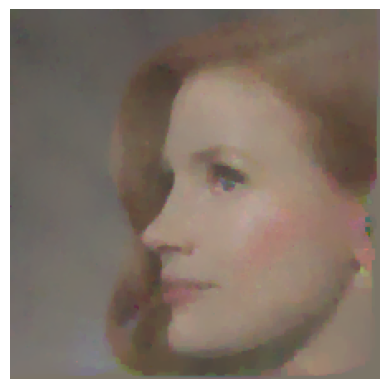

In [14]:
user.plot(reconstructed_data)